In [1]:
import os
import json
import pandas as pd

In [2]:
base_path = "../results"

folders = {

    3: "dev_service_3",
    5: "dev_service_5",
    8: "dev_service_8",
    10: "dev_service_10"

}

In [3]:
data = {}

for k, folder_name in folders.items():

    folder_path = os.path.join(base_path, folder_name)

    data[k] = []

    for file_name in os.listdir(folder_path):

        if not file_name.endswith(".json"):
            continue

        if "_efficiency" in file_name:
            continue

        file_path = os.path.join(folder_path, file_name)

        with open(file_path, "r") as f:
            rows = json.load(f)

        for row in rows:
            row = row.copy()
            row["source_file"] = file_name
            data[k].append(row)

    print(f"K={k}: loaded {len(data[k])} rows")

K=3: loaded 40 rows
K=5: loaded 50 rows
K=8: loaded 65 rows
K=10: loaded 75 rows


In [4]:
df_k3 = pd.DataFrame(data[3])
df_k5 = pd.DataFrame(data[5])
df_k8 = pd.DataFrame(data[8])
df_k10 = pd.DataFrame(data[10])

print("K=3:", df_k3.shape)
print("K=5:", df_k5.shape)
print("K=8:", df_k8.shape)
print("K=10:", df_k10.shape)

K=3: (40, 18)
K=5: (50, 18)
K=8: (65, 18)
K=10: (75, 18)


# K3

### Create binary expected

In [5]:
def get_binary_label(expected_service):
    if expected_service == "general":
        return "general"
    else:
        return "specialist"


df_k3["binary_expected"] = df_k3["expected_service"].apply(get_binary_label)

In [6]:
df_k3["binary_expected"].value_counts()

general       25
specialist    15
Name: binary_expected, dtype: int64

### Unpack scores and confidence and concat with df_k3

In [7]:
scores_k3 = pd.json_normalize(df_k3["scores"])
confidence_k3 = pd.json_normalize(df_k3["confidence"])

In [8]:
df_k3 = pd.concat(
    [
        df_k3.reset_index(drop=True),
        scores_k3.reset_index(drop=True),
        confidence_k3.reset_index(drop=True)
    ],
    axis=1
)

In [9]:
df_k3.columns.tolist()

['routing_method',
 'query',
 'raw_response',
 'predicted_label',
 'model_name',
 'latency_ms',
 'prompt_tokens',
 'completion_tokens',
 'total_tokens',
 'scores',
 'confidence',
 'query_id',
 'expected_service',
 'is_correct',
 'error',
 'specialist_service_count',
 'total_service_count',
 'source_file',
 'binary_expected',
 'abstract_algebra',
 'anatomy',
 'astronomy',
 'k',
 'max',
 'margin',
 'std']

In [10]:
df_k3 = df_k3.rename(columns={"max": "max_score"})

In [11]:
df_k3[
    [
        "query_id",
        "expected_service",
        "binary_expected",
        "predicted_label",
        "abstract_algebra",
        "anatomy",
        "astronomy",
        "max_score",
        "margin",
        "std"
    ]
]

,query_id,expected_service,binary_expected,predicted_label,abstract_algebra,anatomy,astronomy,max_score,margin,std
0,0,abstract_algebra,specialist,abstract_algebra,-4.3750,-12.87500,-12.68750,-4.3750,8.3125,3.9635
1,1,abstract_algebra,specialist,abstract_algebra,7.2500,-11.56250,-12.18750,7.2500,18.8125,9.0192
2,2,abstract_algebra,specialist,abstract_algebra,5.9375,-11.12500,-11.50000,5.9375,17.0625,8.1332
3,3,abstract_algebra,specialist,abstract_algebra,3.6875,-9.56250,-11.25000,3.6875,13.2500,6.6795
4,4,abstract_algebra,specialist,abstract_algebra,-4.7500,-12.68750,-13.31250,-4.7500,7.9375,3.8974
5,5,anatomy,specialist,anatomy,-13.0000,-5.50000,-11.31250,-5.5000,5.8125,3.2125
6,6,anatomy,specialist,anatomy,-13.8750,-6.18750,-13.50000,-6.1875,7.3125,3.5388
7,7,anatomy,specialist,anatomy,-11.3125,-6.15625,-11.37500,-6.1562,5.1562,2.4455
8,8,anatomy,specialist,anatomy,-11.6250,-8.12500,-12.12500,-8.1250,3.5000,1.7795
9,9,anatomy,specialist,anatomy,-13.5625,-7.09375,-12.50000,-7.0938,5.4062,2.8324


In [46]:
df_k3.groupby("binary_expected")[["max_score", "margin", "std"]].agg(
    ["min", "mean", "median", "max"]
)

max_score                            margin                   \
                      min       mean   median    max    min     mean  median   
binary_expected                                                                
general          -15.0625 -11.445000 -11.4375 -8.375    0.0  0.83500  0.6250   
specialist        -8.2500  -4.120833  -6.1562  7.250    3.5  7.75416  5.4375   

                             std                            
                     max     min      mean  median     max  
binary_expected                                             
general           2.6250  0.1792  0.628628  0.4677  1.4669  
specialist       18.8125  1.7795  3.868807  2.8787  9.0192

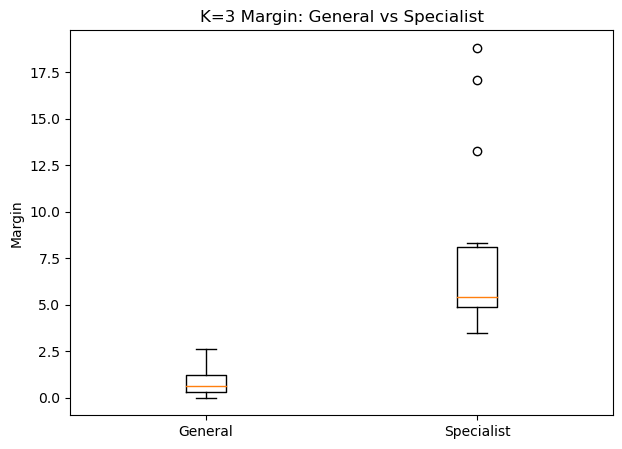

In [47]:
import matplotlib.pyplot as plt

general = df_k3.loc[df_k3["binary_expected"] == "general", "margin"]
specialist = df_k3.loc[df_k3["binary_expected"] == "specialist", "margin"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Margin")
plt.title("K=3 Margin: General vs Specialist")
plt.show()

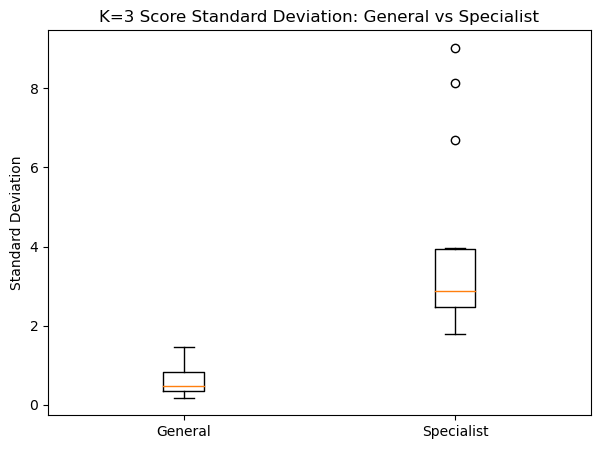

In [13]:
import matplotlib.pyplot as plt

general = df_k3.loc[df_k3["binary_expected"] == "general", "std"]
specialist = df_k3.loc[df_k3["binary_expected"] == "specialist", "std"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Standard Deviation")
plt.title("K=3 Score Standard Deviation: General vs Specialist")

plt.show()

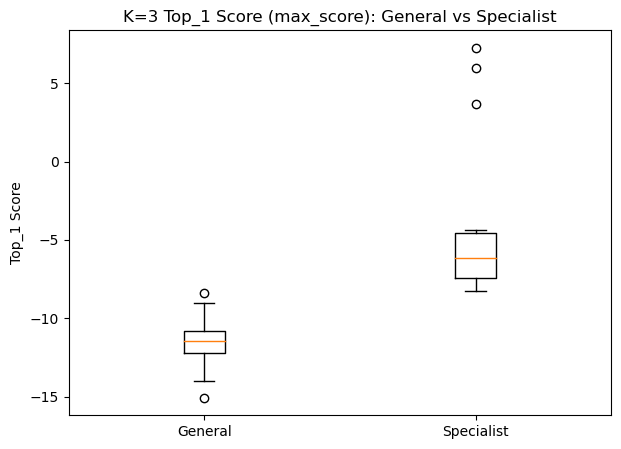

In [14]:
import matplotlib.pyplot as plt

general = df_k3.loc[df_k3["binary_expected"] == "general", "max_score"]
specialist = df_k3.loc[df_k3["binary_expected"] == "specialist", "max_score"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Top_1 Score")
plt.title("K=3 Top_1 Score (max_score): General vs Specialist")

plt.show()

# K5

In [15]:
def get_binary_label(expected_service):
    if expected_service == "general":
        return "general"
    else:
        return "specialist"


df_k5["binary_expected"] = df_k5["expected_service"].apply(get_binary_label)

In [16]:
df_k5["binary_expected"].value_counts()

specialist    25
general       25
Name: binary_expected, dtype: int64

In [17]:
scores_k5 = pd.json_normalize(df_k5["scores"])
confidence_k5 = pd.json_normalize(df_k5["confidence"])

In [18]:
df_k5 = pd.concat(
    [
        df_k5.reset_index(drop=True),
        scores_k5.reset_index(drop=True),
        confidence_k5.reset_index(drop=True)
    ],
    axis=1
)

In [19]:
df_k5.columns.tolist()

['routing_method',
 'query',
 'raw_response',
 'predicted_label',
 'model_name',
 'latency_ms',
 'prompt_tokens',
 'completion_tokens',
 'total_tokens',
 'scores',
 'confidence',
 'query_id',
 'expected_service',
 'is_correct',
 'error',
 'specialist_service_count',
 'total_service_count',
 'source_file',
 'binary_expected',
 'abstract_algebra',
 'anatomy',
 'astronomy',
 'business_ethics',
 'college_computer_science',
 'k',
 'max',
 'margin',
 'std']

In [20]:
df_k5 = df_k5.rename(columns={"max": "max_score"})

In [21]:
df_k5[
    [
        "query_id",
        "expected_service",
        "binary_expected",
        "predicted_label",

        "abstract_algebra",
        "anatomy",
        "astronomy",
        "business_ethics",
        "college_computer_science",

        "max_score",
        "margin",
        "std"
    ]
]

,query_id,expected_service,binary_expected,predicted_label,abstract_algebra,anatomy,astronomy,business_ethics,college_computer_science,max_score,margin,std
0,0,abstract_algebra,specialist,abstract_algebra,-4.4375,-12.87500,-12.75000,-14.37500,-10.75000,-4.4375,6.3125,3.4954
1,1,abstract_algebra,specialist,abstract_algebra,7.1250,-11.62500,-12.31250,-12.81250,-8.62500,7.1250,15.7500,7.5292
2,2,abstract_algebra,specialist,abstract_algebra,6.0000,-11.25000,-11.62500,-12.68750,-7.78125,6.0000,13.7812,6.9327
3,3,abstract_algebra,specialist,abstract_algebra,3.6250,-9.62500,-11.37500,-12.37500,-6.37500,3.6250,10.0000,5.7957
4,4,abstract_algebra,specialist,abstract_algebra,-4.7500,-12.87500,-13.43750,-14.81250,-10.06250,-4.7500,5.3125,3.5709
5,5,anatomy,specialist,anatomy,-12.9375,-5.56250,-11.37500,-13.81250,-13.12500,-5.5625,5.8125,3.0076
6,6,anatomy,specialist,anatomy,-14.0000,-6.18750,-13.62500,-14.00000,-13.87500,-6.1875,7.4375,3.0780
7,7,anatomy,specialist,anatomy,-11.3750,-6.09375,-11.56250,-13.00000,-11.87500,-6.0938,5.2812,2.4106
8,8,anatomy,specialist,anatomy,-11.6250,-8.06250,-12.12500,-14.12500,-12.31250,-8.0625,3.5625,1.9830
9,9,anatomy,specialist,anatomy,-13.6250,-7.21875,-12.37500,-14.31250,-13.75000,-7.2188,5.1562,2.5971


In [22]:
df_k5.groupby("binary_expected")[["max_score", "margin", "std"]].agg(
    ["min", "mean", "median", "max"]
)

max_score                             margin                   \
                      min       mean   median    max     min     mean  median   
binary_expected                                                                 
general          -14.5625 -11.085000 -11.1875 -8.125  0.1250  0.78750  0.5625   
specialist        -8.3125  -5.122508  -6.8750  7.125  2.2812  5.95124  5.2812   

                           std                            
                   max     min      mean  median     max  
binary_expected                                           
general           2.75  0.1837  0.765884  0.7185  1.7016  
specialist       15.75  1.5491  3.030748  2.5649  7.5292

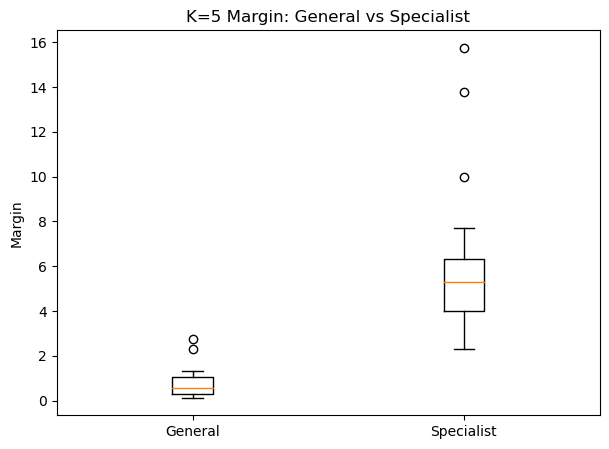

In [48]:
import matplotlib.pyplot as plt

general = df_k5.loc[df_k5["binary_expected"] == "general", "margin"]
specialist = df_k5.loc[df_k5["binary_expected"] == "specialist", "margin"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Margin")
plt.title("K=5 Margin: General vs Specialist")
plt.show()

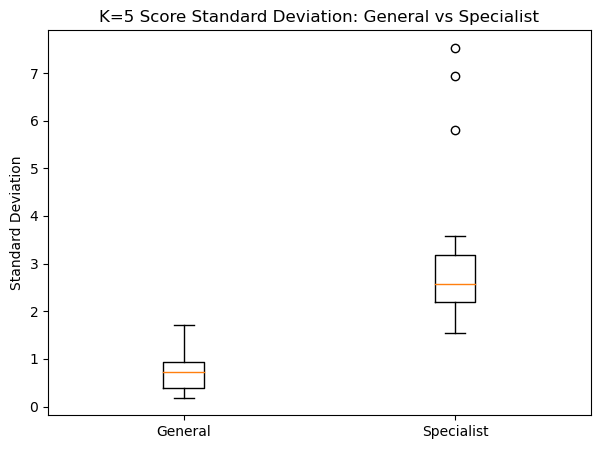

In [24]:
import matplotlib.pyplot as plt

general = df_k5.loc[df_k5["binary_expected"] == "general", "std"]
specialist = df_k5.loc[df_k5["binary_expected"] == "specialist", "std"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Standard Deviation")
plt.title("K=5 Score Standard Deviation: General vs Specialist")

plt.show()

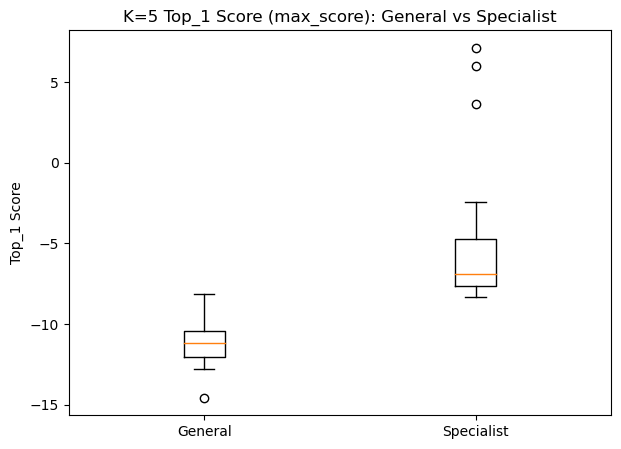

In [25]:
import matplotlib.pyplot as plt

general = df_k5.loc[df_k5["binary_expected"] == "general", "max_score"]
specialist = df_k5.loc[df_k5["binary_expected"] == "specialist", "max_score"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Top_1 Score")
plt.title("K=5 Top_1 Score (max_score): General vs Specialist")

plt.show()

In [26]:
# Specialist queries with the LOWEST margins
df_k5[df_k5["binary_expected"] == "specialist"][
    ["query_id", "expected_service", "predicted_label", "max_score", "margin", "std"]
].nsmallest(5, "margin")

,query_id,expected_service,predicted_label,max_score,margin,std
18,18,business_ethics,business_ethics,-7.7812,2.2812,1.5491
22,22,college_computer_science,college_computer_science,-8.1250,2.8750,1.7829
8,8,anatomy,anatomy,-8.0625,3.5625,1.9830
12,12,astronomy,astronomy,-8.3125,3.6875,2.0115
24,24,college_computer_science,college_computer_science,-7.6250,3.6875,2.4273


In [27]:
# General queries with the HIGHEST margins
df_k5[df_k5["binary_expected"] == "general"][
    ["query_id", "expected_service", "predicted_label", "max_score", "margin", "std"]
].nlargest(5, "margin")

,query_id,expected_service,predicted_label,max_score,margin,std
44,44,general,anatomy,-9.4375,2.7500,1.6059
27,27,general,anatomy,-8.8750,2.3125,1.7016
32,32,general,business_ethics,-11.5000,1.3125,0.7699
30,30,general,business_ethics,-12.7500,1.2500,0.7185
36,36,general,business_ethics,-8.7500,1.2500,1.5492


# K8

In [28]:
def get_binary_label(expected_service):
    if expected_service == "general":
        return "general"
    else:
        return "specialist"


df_k8["binary_expected"] = df_k8["expected_service"].apply(get_binary_label)

In [29]:
df_k8["binary_expected"].value_counts()

specialist    40
general       25
Name: binary_expected, dtype: int64

In [30]:
scores_k8 = pd.json_normalize(df_k8["scores"])
confidence_k8 = pd.json_normalize(df_k8["confidence"])

df_k8 = pd.concat(
    [
        df_k8.reset_index(drop=True),
        scores_k8.reset_index(drop=True),
        confidence_k8.reset_index(drop=True)
    ],
    axis=1
)

In [31]:
df_k8.columns.tolist()

['routing_method',
 'query',
 'raw_response',
 'predicted_label',
 'model_name',
 'latency_ms',
 'prompt_tokens',
 'completion_tokens',
 'total_tokens',
 'scores',
 'confidence',
 'query_id',
 'expected_service',
 'is_correct',
 'error',
 'specialist_service_count',
 'total_service_count',
 'source_file',
 'binary_expected',
 'abstract_algebra',
 'anatomy',
 'astronomy',
 'business_ethics',
 'college_computer_science',
 'high_school_chemistry',
 'high_school_geography',
 'jurisprudence',
 'k',
 'max',
 'margin',
 'std']

In [32]:
df_k8 = df_k8.rename(columns={"max": "max_score"})

In [33]:
pd.set_option("display.max_rows", None)

In [34]:
df_k8[
    [
        "query_id",
        "expected_service",
        "binary_expected",
        "predicted_label",

        "abstract_algebra",
        "anatomy",
        "astronomy",
        "business_ethics",
        "college_computer_science",
        "high_school_chemistry",
        "high_school_geography",
        "jurisprudence",

        "max_score",
        "margin",
        "std"
    ]
]

,query_id,expected_service,binary_expected,predicted_label,abstract_algebra,anatomy,astronomy,business_ethics,college_computer_science,high_school_chemistry,high_school_geography,jurisprudence,max_score,margin,std
0,0,abstract_algebra,specialist,abstract_algebra,-4.3750,-12.87500,-12.68750,-14.37500,-10.62500,-12.3125,-14.7500,-13.00000,-4.3750,6.2500,3.0709
1,1,abstract_algebra,specialist,abstract_algebra,7.2500,-11.56250,-12.18750,-12.75000,-8.62500,-11.0625,-13.7500,-11.62500,7.2500,15.8750,6.4034
2,2,abstract_algebra,specialist,abstract_algebra,5.9375,-11.12500,-11.50000,-12.62500,-7.81250,-10.5625,-13.6875,-11.75000,5.9375,13.7500,5.9189
3,3,abstract_algebra,specialist,abstract_algebra,3.6875,-9.56250,-11.25000,-12.25000,-6.25000,-10.4375,-13.9375,-10.25000,3.6875,9.9375,5.1490
4,4,abstract_algebra,specialist,abstract_algebra,-4.7500,-12.87500,-13.31250,-14.81250,-10.00000,-12.6250,-14.5625,-13.00000,-4.7500,5.2500,3.0602
5,5,anatomy,specialist,anatomy,-12.8750,-5.56250,-11.37500,-13.81250,-13.12500,-12.5000,-13.6250,-13.18750,-5.5625,5.8125,2.5360
6,6,anatomy,specialist,anatomy,-13.9375,-6.15625,-13.56250,-14.06250,-13.81250,-12.5625,-13.8125,-13.81250,-6.1562,6.4062,2.5170
7,7,anatomy,specialist,anatomy,-11.3125,-6.12500,-11.56250,-13.00000,-12.00000,-12.3125,-13.5000,-12.62500,-6.1250,5.1875,2.1602
8,8,anatomy,specialist,anatomy,-11.6250,-8.12500,-12.12500,-14.18750,-12.37500,-12.5000,-13.2500,-12.50000,-8.1250,3.5000,1.6621
9,9,anatomy,specialist,anatomy,-13.4375,-7.21875,-12.50000,-14.31250,-13.68750,-12.0625,-13.8125,-13.93750,-7.2188,4.8438,2.1601


In [35]:
df_k8.groupby("binary_expected")[["max_score", "margin", "std"]].agg(
    ["min", "mean", "median", "max"]
)

max_score                            margin                    \
                      min       mean   median    max    min      mean  median   
binary_expected                                                                 
general          -13.8125 -10.218748 -10.5625 -1.375  0.000  1.266248  0.7500   
specialist       -11.0625  -5.596090  -7.0938  7.250  0.125  4.953127  4.5625   

                            std                             
                    max     min      mean   median     max  
binary_expected                                             
general           5.625  0.2669  0.991128  0.79790  2.6669  
specialist       15.875  0.4754  2.467288  2.20205  6.4034

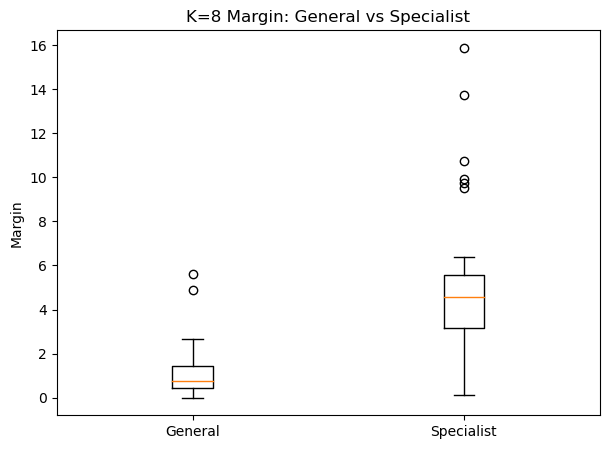

In [36]:
import matplotlib.pyplot as plt

general = df_k8.loc[df_k8["binary_expected"] == "general", "margin"]
specialist = df_k8.loc[df_k8["binary_expected"] == "specialist", "margin"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Margin")
plt.title("K=8 Margin: General vs Specialist")
plt.show()

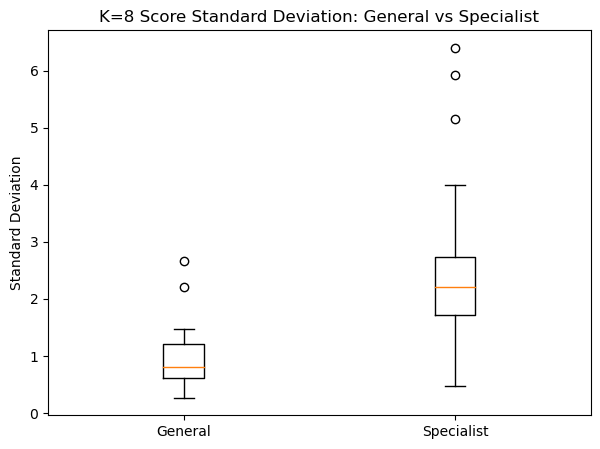

In [37]:
import matplotlib.pyplot as plt

general = df_k8.loc[df_k8["binary_expected"] == "general", "std"]
specialist = df_k8.loc[df_k8["binary_expected"] == "specialist", "std"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Standard Deviation")
plt.title("K=8 Score Standard Deviation: General vs Specialist")

plt.show()

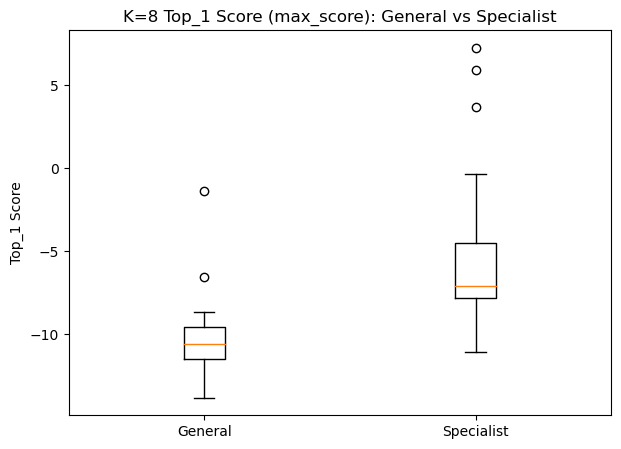

In [38]:
import matplotlib.pyplot as plt

general = df_k8.loc[df_k8["binary_expected"] == "general", "max_score"]
specialist = df_k8.loc[df_k8["binary_expected"] == "specialist", "max_score"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Top_1 Score")
plt.title("K=8 Top_1 Score (max_score): General vs Specialist")

plt.show()

In [39]:
# Specialist queries with the LOWEST margins

df_k8[df_k8["binary_expected"] == "specialist"][
    ["query_id", "expected_service", "predicted_label", "max_score", "margin", "std"]
].nsmallest(5, "margin")

,query_id,expected_service,predicted_label,max_score,margin,std
34,34,high_school_geography,high_school_geography,-11.0625,0.1250,0.4754
33,33,high_school_geography,business_ethics,-7.7812,0.3438,1.8761
45,45,jurisprudence,jurisprudence,-9.8750,1.3750,1.1693
32,32,high_school_geography,jurisprudence,-9.6875,1.4375,0.8092
12,12,astronomy,astronomy,-8.3750,1.5000,2.0752


In [40]:
# General queries with the HIGHEST margins
df_k8[df_k8["binary_expected"] == "general"][
    ["query_id", "expected_service", "predicted_label", "max_score", "margin", "std"]
].nlargest(5, "margin")

,query_id,expected_service,predicted_label,max_score,margin,std
50,50,general,high_school_geography,-1.3750,5.6250,2.6669
42,42,general,jurisprudence,-6.5312,4.9062,2.2086
40,40,general,jurisprudence,-10.0625,2.6875,1.4520
59,59,general,anatomy,-9.5625,2.6875,1.3114
37,37,general,anatomy,-9.0000,2.1250,1.4638


In [41]:
pd.set_option("display.max_colwidth", None)

In [45]:
df_k8.loc[
    df_k8["query_id"].isin([30, 31, 32, 33, 34, 50]),
    [
        "query_id",
        "query",
        "expected_service",
        "predicted_label",
        "high_school_geography",
        "business_ethics",
        "jurisprudence",
        "max_score",
        "margin"
    ]
]

,query_id,query,expected_service,predicted_label,high_school_geography,business_ethics,jurisprudence,max_score,margin
30,30,The rate of natural increase of a population is found by subtracting the,high_school_geography,high_school_geography,-9.4375,-13.68750,-12.1250,-9.4375,1.5000
31,31,"During the third stage of the demographic transition model, which of the following is true?",high_school_geography,high_school_geography,-5.5625,-13.62500,-12.8125,-5.5625,6.1250
32,32,Which of the following statements is NOT accurate regarding the services provided by local governments in the United States?,high_school_geography,jurisprudence,-11.6250,-11.12500,-9.6875,-9.6875,1.4375
33,33,The practice of hiring a foreign third-party service provider to run an operation is called,high_school_geography,business_ethics,-12.3125,-7.78125,-8.1250,-7.7812,0.3438
34,34,Which one of the following items is an example of nonmaterial culture?,high_school_geography,high_school_geography,-11.0625,-12.50000,-11.2500,-11.0625,0.1250
50,50,_____________ is a natural outcome when combining demographic and geographic variables.,general,high_school_geography,-1.3750,-8.18750,-7.0000,-1.3750,5.6250


# K10

In [43]:
def get_binary_label(expected_service):
    if expected_service == "general":
        return "general"
    else:
        return "specialist"


df_k10["binary_expected"] = df_k10["expected_service"].apply(get_binary_label)

In [61]:
df_k10["binary_expected"].value_counts()

specialist    50
general       25
Name: binary_expected, dtype: int64

In [62]:

scores_k10 = pd.json_normalize(df_k10["scores"])
confidence_k10 = pd.json_normalize(df_k10["confidence"])

df_k10 = pd.concat(
    [
        df_k10.reset_index(drop=True),
        scores_k10.reset_index(drop=True),
        confidence_k10.reset_index(drop=True)
    ],
    axis=1
)


In [63]:
df_k10.columns.tolist()

['routing_method',
 'query',
 'raw_response',
 'predicted_label',
 'model_name',
 'latency_ms',
 'prompt_tokens',
 'completion_tokens',
 'total_tokens',
 'scores',
 'confidence',
 'query_id',
 'expected_service',
 'is_correct',
 'error',
 'specialist_service_count',
 'total_service_count',
 'source_file',
 'binary_expected',
 'abstract_algebra',
 'anatomy',
 'astronomy',
 'business_ethics',
 'college_computer_science',
 'high_school_chemistry',
 'high_school_geography',
 'jurisprudence',
 'world_religions',
 'formal_logic',
 'k',
 'max',
 'margin',
 'std']

In [64]:
df_k10 = df_k10.rename(columns={"max": "max_score"})

In [ ]:



df_k3[
    [
        "query_id",
        "expected_service",
        "binary_expected",
        "predicted_label",
        "abstract_algebra",
        "anatomy",
        "astronomy",
        "max_score",
        "margin",
        "std"
    ]
]

df_k3.groupby("binary_expected")[["max", "margin", "std"]].agg(
    ["min", "mean", "median", "max"]
)

import matplotlib.pyplot as plt

general = df_k3.loc[df_k3["binary_expected"] == "general", "margin"]
specialist = df_k3.loc[df_k3["binary_expected"] == "specialist", "margin"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Margin")
plt.title("K=3 Margin: General vs Specialist")
plt.show()

import matplotlib.pyplot as plt

general = df_k3.loc[df_k3["binary_expected"] == "general", "std"]
specialist = df_k3.loc[df_k3["binary_expected"] == "specialist", "std"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Standard Deviation")
plt.title("K=3 Score Standard Deviation: General vs Specialist")

plt.show()

import matplotlib.pyplot as plt

general = df_k3.loc[df_k3["binary_expected"] == "general", "max_score"]
specialist = df_k3.loc[df_k3["binary_expected"] == "specialist", "max_score"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Top_1 Score")
plt.title("K=3 Top_1 Score (max_score): General vs Specialist")

plt.show()

In [3]:
all_rows = []

for k, folder_name in folders.items():

    folder_path = os.path.join(base_path, folder_name)

    for file_name in os.listdir(folder_path):

        if not file_name.endswith(".json"):
            continue
            
        if "_efficiency" in file_name:
            continue

        file_path = os.path.join(folder_path, file_name)

        with open(file_path, "r") as f:
            data = json.load(f)

        for row in data:
            row["source_file"] = file_name
            all_rows.append(row)

In [4]:
df = pd.DataFrame(all_rows)

In [5]:
confidence_df = pd.json_normalize(df["confidence"])

confidence_df = confidence_df.rename(
    columns={"max": "max_score"}
)

df = pd.concat([df, confidence_df], axis=1)

In [6]:
df

,routing_method,query,raw_response,predicted_label,model_name,latency_ms,prompt_tokens,completion_tokens,total_tokens,scores,...,expected_service,is_correct,error,specialist_service_count,total_service_count,source_file,k,max_score,margin,std
0,cross-encoder,Find all c in Z_3 such that Z_3[x]/(x^2 + c) i...,None,abstract_algebra,Qwen/Qwen3-Reranker-4B,409.794751,266,0,266,"{'abstract_algebra': -4.375, 'anatomy': -12.87...",...,abstract_algebra,True,None,3,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,3,-4.3750,8.3125,3.9635
1,cross-encoder,Statement 1 | If aH is an element of a factor ...,None,abstract_algebra,Qwen/Qwen3-Reranker-4B,46.805847,326,0,326,"{'abstract_algebra': 7.25, 'anatomy': -11.5625...",...,abstract_algebra,True,None,3,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,3,7.2500,18.8125,9.0192
2,cross-encoder,Statement 1 | Every element of a group generat...,None,abstract_algebra,Qwen/Qwen3-Reranker-4B,45.844679,293,0,293,"{'abstract_algebra': 5.9375, 'anatomy': -11.12...",...,abstract_algebra,True,None,3,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,3,5.9375,17.0625,8.1332
3,cross-encoder,Statement 1| Every function from a finite set ...,None,abstract_algebra,Qwen/Qwen3-Reranker-4B,45.773243,290,0,290,"{'abstract_algebra': 3.6875, 'anatomy': -9.562...",...,abstract_algebra,True,None,3,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,3,3.6875,13.2500,6.6795
4,cross-encoder,Find the characteristic of the ring 2Z.,None,abstract_algebra,Qwen/Qwen3-Reranker-4B,44.889348,221,0,221,"{'abstract_algebra': -4.75, 'anatomy': -12.687...",...,abstract_algebra,True,None,3,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,3,-4.7500,7.9375,3.8974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225,cross-encoder,What is the sign of the covenant for Jewish m...,None,world_religions,Qwen/Qwen3-Reranker-4B,102.985758,704,0,704,"{'abstract_algebra': -13.4375, 'anatomy': -11....",...,world_religions,True,None,10,10,cross-encoder_Qwen-Qwen3-Reranker-4B.json,10,-11.3750,0.5000,0.6459
226,cross-encoder,What is the Second Gem in Buddhism?,None,world_religions,Qwen/Qwen3-Reranker-4B,101.864317,674,0,674,"{'abstract_algebra': -12.125, 'anatomy': -11.4...",...,world_religions,True,None,10,10,cross-encoder_Qwen-Qwen3-Reranker-4B.json,10,-7.8125,3.6250,1.4620
227,cross-encoder,"In which dynasty was the ""Mandate of Heaven"" ...",None,world_religions,Qwen/Qwen3-Reranker-4B,104.886513,804,0,804,"{'abstract_algebra': -13.75, 'anatomy': -13.12...",...,world_religions,True,None,10,10,cross-encoder_Qwen-Qwen3-Reranker-4B.json,10,-10.1250,1.4375,1.0492
228,cross-encoder,Which Japanese government promoted a kind of ...,None,world_religions,Qwen/Qwen3-Reranker-4B,104.532194,784,0,784,"{'abstract_algebra': -13.8125, 'anatomy': -13....",...,world_religions,True,None,10,10,cross-encoder_Qwen-Qwen3-Reranker-4B.json,10,-10.0000,2.4375,1.0984


In [7]:
df_k3 = df[df["k"] == 3].copy()
df_k3 = df_k3.reset_index(drop=True)

scores_k3 = pd.json_normalize(df_k3["scores"])

df_k3 = pd.concat([df_k3, scores_k3], axis=1)

In [8]:
df_k3[
    [
        "query",
        "expected_service",
        "predicted_label",
        "max_score",
        "margin",
        "std",
        "abstract_algebra",
        "anatomy",
        "astronomy"
    ]
]

,query,expected_service,predicted_label,max_score,margin,std,abstract_algebra,anatomy,astronomy
0,Find all c in Z_3 such that Z_3[x]/(x^2 + c) i...,abstract_algebra,abstract_algebra,-4.3750,8.3125,3.9635,-4.3750,-12.87500,-12.68750
1,Statement 1 | If aH is an element of a factor ...,abstract_algebra,abstract_algebra,7.2500,18.8125,9.0192,7.2500,-11.56250,-12.18750
2,Statement 1 | Every element of a group generat...,abstract_algebra,abstract_algebra,5.9375,17.0625,8.1332,5.9375,-11.12500,-11.50000
3,Statement 1| Every function from a finite set ...,abstract_algebra,abstract_algebra,3.6875,13.2500,6.6795,3.6875,-9.56250,-11.25000
4,Find the characteristic of the ring 2Z.,abstract_algebra,abstract_algebra,-4.7500,7.9375,3.8974,-4.7500,-12.68750,-13.31250
5,What is the embryological origin of the hyoid ...,anatomy,anatomy,-5.5000,5.8125,3.2125,-13.0000,-5.50000,-11.31250
6,Which of these branches of the trigeminal nerv...,anatomy,anatomy,-6.1875,7.3125,3.5388,-13.8750,-6.18750,-13.50000
7,The pleura,anatomy,anatomy,-6.1562,5.1562,2.4455,-11.3125,-6.15625,-11.37500
8,In Angle's Class II Div 2 occlusion there is,anatomy,anatomy,-8.1250,3.5000,1.7795,-11.6250,-8.12500,-12.12500
9,Which of the following is the body cavity that...,anatomy,anatomy,-7.0938,5.4062,2.8324,-13.5625,-7.09375,-12.50000


In [9]:
df_k10 = df[df["k"] == 10].copy()
df_k10 = df_k10.reset_index(drop=True)

scores_k10 = pd.json_normalize(df_k10["scores"])

df_k10 = pd.concat([df_k10, scores_k10], axis=1)

In [10]:
df_k10[
    [
        "query",
        "expected_service",
        "predicted_label",
        "max_score",
        "margin",
        "std",
        "abstract_algebra",
        "anatomy",
        "astronomy",
        "business_ethics",
        "college_computer_science",
        "formal_logic",
        "high_school_chemistry",
        "high_school_geography",
        "jurisprudence",
        "world_religions"
        
        
    ]
]

,query,expected_service,predicted_label,max_score,margin,std,abstract_algebra,anatomy,astronomy,business_ethics,college_computer_science,formal_logic,high_school_chemistry,high_school_geography,jurisprudence,world_religions
0,Find all c in Z_3 such that Z_3[x]/(x^2 + c) i...,abstract_algebra,abstract_algebra,-4.4375,6.2500,2.7596,-4.4375,-12.8750,-12.6875,-14.3750,-10.6875,-11.0625,-12.2500,-14.6875,-13.0000,-13.1250
1,Statement 1 | If aH is an element of a factor ...,abstract_algebra,abstract_algebra,7.2500,11.1250,6.0035,7.2500,-11.4375,-12.3125,-12.7500,-8.6250,-3.8750,-11.1250,-13.6875,-11.5625,-11.4375
2,Statement 1 | Every element of a group generat...,abstract_algebra,abstract_algebra,6.1250,10.5625,5.5779,6.1250,-11.1875,-11.6250,-12.6250,-7.8750,-4.4375,-10.7500,-13.8750,-11.6875,-10.3125
3,Statement 1| Every function from a finite set ...,abstract_algebra,abstract_algebra,3.6250,6.0000,5.0049,3.6250,-9.6250,-11.2500,-12.3125,-6.2500,-2.3750,-10.5625,-13.8750,-10.1250,-10.0000
4,Find the characteristic of the ring 2Z.,abstract_algebra,abstract_algebra,-4.7500,5.2500,2.7897,-4.7500,-12.7500,-13.3750,-14.8125,-10.0000,-11.3750,-12.6250,-14.7500,-12.9375,-13.3125
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,What is the sign of the covenant for Jewish m...,world_religions,world_religions,-11.3750,0.5000,0.6459,-13.4375,-11.8750,-13.0000,-13.5625,-12.8750,-13.0000,-12.6250,-13.1875,-12.5625,-11.3750
71,What is the Second Gem in Buddhism?,world_religions,world_religions,-7.8125,3.6250,1.4620,-12.1250,-11.4375,-11.4375,-12.9375,-11.9375,-12.7500,-12.6875,-13.2500,-11.8750,-7.8125
72,"In which dynasty was the ""Mandate of Heaven"" ...",world_religions,world_religions,-10.1250,1.4375,1.0492,-13.7500,-13.1250,-13.1250,-13.3750,-13.3750,-13.3125,-13.3125,-12.6250,-11.5625,-10.1250
73,Which Japanese government promoted a kind of ...,world_religions,world_religions,-10.0000,2.4375,1.0984,-13.8125,-13.3750,-12.8750,-13.7500,-13.3750,-14.0000,-13.3750,-12.4375,-12.6875,-10.0000


In [11]:
def get_binary_label(expected_service):
    if expected_service == "general":
        return "general"
    else:
        return "specialist"


df["binary_expected"] = df["expected_service"].apply(get_binary_label)

In [15]:
df[
    [
        "expected_service",
        "binary_expected",
        "k",
        "max_score",
        "margin",
        "std"
    ]
].head(10)

,expected_service,binary_expected,k,max_score,margin,std
0,abstract_algebra,specialist,3,-4.3750,8.3125,3.9635
1,abstract_algebra,specialist,3,7.2500,18.8125,9.0192
2,abstract_algebra,specialist,3,5.9375,17.0625,8.1332
3,abstract_algebra,specialist,3,3.6875,13.2500,6.6795
4,abstract_algebra,specialist,3,-4.7500,7.9375,3.8974
5,anatomy,specialist,3,-5.5000,5.8125,3.2125
6,anatomy,specialist,3,-6.1875,7.3125,3.5388
7,anatomy,specialist,3,-6.1562,5.1562,2.4455
8,anatomy,specialist,3,-8.1250,3.5000,1.7795
9,anatomy,specialist,3,-7.0938,5.4062,2.8324


In [17]:
summary = df.groupby(["k", "binary_expected"])[["max_score", "margin", "std"]].agg(["count", "mean", "median", "min", "max"])
summary

max_score                                     margin  \
                       count       mean   median      min    max  count   
k  binary_expected                                                        
3  general                25 -11.445000 -11.4375 -15.0625 -8.375     25   
   specialist             15  -4.120833  -6.1562  -8.2500  7.250     15   
5  general                25 -11.085000 -11.1875 -14.5625 -8.125     25   
   specialist             25  -5.122508  -6.8750  -8.3125  7.125     25   
8  general                25 -10.218748 -10.5625 -13.8125 -1.375     25   
   specialist             40  -5.596090  -7.0938 -11.0625  7.250     40   
10 general                25  -9.958752 -10.5000 -12.1250 -1.375     25   
   specialist             50  -5.358122  -7.0625 -11.3750  7.250     50   

                                                         std            \
                        mean   median     min      max count      mean   
k  binary_expected                                                       
3  general          0.835000  0.62500  0.0000   2.6250    25  0.628628   
   specialist       7.754160  5.43750  3.5000  18.8125    15  3.868807   
5  general          0.787500  0.56250  0.1250   2.7500    25  0.765884   
   specialist       5.951240  5.28120  2.2812  15.7500    25  3.030748   
8  general          1.266248  0.75000  0.0000   5.6250    25  0.991128   
   specialist       4.953127  4.56250  0.1250  15.8750    40  2.467288   
10 general          1.225004  0.68750  0.0625   5.7188    25  1.015508   
   specialist       4.566252  4.10935  0.2188  11.1250    50  2.337576   

                                             
                     median     min     max  
k  binary_expected                           
3  general          0.46770  0.1792  1.4669  
   specialist       2.87870  1.7795  9.0192  
5  general          0.71850  0.1837  1.7016  
   specialist       2.56490  1.5491  7.5292  
8  general          0.79790  0.2669  2.6669  
   specialist       2.20205  0.4754  6.4034  
10 general          0.96640  0.2982  2.3701  
   specialist       2.05045  0.6459  6.0035

In [18]:
def get_binary_target(label):
    if label == "specialist":
        return 1
    else:
        return 0


df["binary_target"] = df["binary_expected"].apply(get_binary_target)

In [19]:
df_k10 = df[df["k"] == 10]

In [20]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(
    df_k10["binary_target"],
    df_k10["max_score"]
)

auc = roc_auc_score(
    df_k10["binary_target"],
    df_k10["max_score"]
)

print("AUC:", auc)

AUC: 0.8952


In [21]:
roc_df = pd.DataFrame({
    "threshold": thresholds,
    "true_positive_rate": tpr,
    "false_positive_rate": fpr
})

roc_df

,threshold,true_positive_rate,false_positive_rate
0,8.2500,0.00,0.00
1,7.2500,0.02,0.00
2,6.1250,0.04,0.00
3,3.6250,0.08,0.00
4,-1.1875,0.16,0.00
5,-1.3750,0.16,0.04
6,-2.3125,0.20,0.04
7,-2.5000,0.24,0.04
8,-3.7500,0.26,0.04
9,-4.4375,0.30,0.04


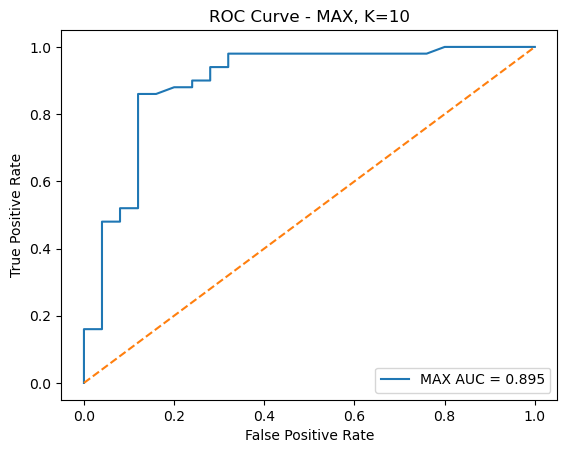

In [22]:
import matplotlib.pyplot as plt

plt.plot(fpr, tpr, label=f"MAX AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - MAX, K=10")
plt.legend()

plt.show()

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

df_k10 = df[df["k"] == 10]

# MAX
fpr_max, tpr_max, thresholds_max = roc_curve(
    df_k10["binary_target"],
    df_k10["max_score"]
)

auc_max = roc_auc_score(
    df_k10["binary_target"],
    df_k10["max_score"]
)

# Margin
fpr_margin, tpr_margin, thresholds_margin = roc_curve(
    df_k10["binary_target"],
    df_k10["margin"]
)

auc_margin = roc_auc_score(
    df_k10["binary_target"],
    df_k10["margin"]
)

# STD
fpr_std, tpr_std, thresholds_std = roc_curve(
    df_k10["binary_target"],
    df_k10["std"]
)

auc_std = roc_auc_score(
    df_k10["binary_target"],
    df_k10["std"]
)

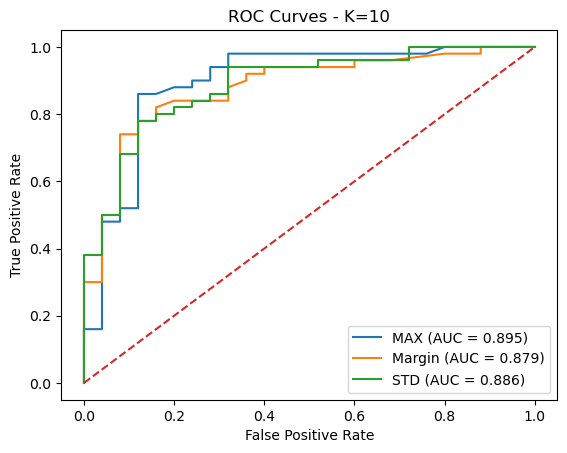

In [24]:
plt.plot(
    fpr_max,
    tpr_max,
    label=f"MAX (AUC = {auc_max:.3f})"
)

plt.plot(
    fpr_margin,
    tpr_margin,
    label=f"Margin (AUC = {auc_margin:.3f})"
)

plt.plot(
    fpr_std,
    tpr_std,
    label=f"STD (AUC = {auc_std:.3f})"
)

plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - K=10")
plt.legend()

plt.show()

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score

df_k10 = df[df["k"] == 10]

fpr, tpr, thresholds = roc_curve(
    df_k10["binary_target"],
    df_k10["margin"]
)

margin_auc = roc_auc_score(
    df_k10["binary_target"],
    df_k10["margin"]
)

margin_roc = pd.DataFrame({
    "threshold": thresholds,
    "TPR": tpr,
    "FPR": fpr
})

margin_roc

,threshold,TPR,FPR
0,12.1250,0.00,0.00
1,11.1250,0.02,0.00
2,6.6875,0.18,0.00
3,6.2500,0.26,0.00
4,5.8125,0.30,0.00
5,5.7188,0.30,0.04
6,5.2500,0.38,0.04
7,4.3125,0.50,0.04
8,4.2188,0.50,0.08
9,2.7500,0.74,0.08


In [29]:
df_k10 = df[df["k"] == 10].copy()

targets = [0.10, 0.20, 0.25, 0.30, 0.40, 0.50]

In [30]:
for target in targets:

    threshold = df_k10["margin"].quantile(target)

    print(
        "Target fallback:",
        target,
        "Margin threshold:",
        threshold
    )

Target fallback: 0.1 Margin threshold: 0.3125
Target fallback: 0.2 Margin threshold: 0.6625000000000001
Target fallback: 0.25 Margin threshold: 1.15625
Target fallback: 0.3 Margin threshold: 1.45
Target fallback: 0.4 Margin threshold: 2.0625000000000004
Target fallback: 0.5 Margin threshold: 2.9375


In [31]:
results = []

for target in targets:

    threshold = df_k10["margin"].quantile(target)

    predictions = []

    for margin in df_k10["margin"]:

        if margin > threshold:
            predictions.append("specialist")
        else:
            predictions.append("general")

    temp = df_k10.copy()
    temp["gate_prediction"] = predictions

    tp = (
        (temp["binary_expected"] == "specialist") &
        (temp["gate_prediction"] == "specialist")
    ).sum()

    fn = (
        (temp["binary_expected"] == "specialist") &
        (temp["gate_prediction"] == "general")
    ).sum()

    fp = (
        (temp["binary_expected"] == "general") &
        (temp["gate_prediction"] == "specialist")
    ).sum()

    tn = (
        (temp["binary_expected"] == "general") &
        (temp["gate_prediction"] == "general")
    ).sum()

    tpr = tp / (tp + fn)
    fpr = fp / (fp + tn)

    results.append({
        "target_fallback": target,
        "margin_threshold": threshold,
        "TPR": tpr,
        "FPR": fpr
    })

results_df = pd.DataFrame(results)

results_df

,target_fallback,margin_threshold,TPR,FPR
0,0.10,0.31250,0.96,0.68
1,0.20,0.66250,0.94,0.52
2,0.25,1.15625,0.92,0.40
3,0.30,1.45000,0.88,0.32
4,0.40,2.06250,0.82,0.16
5,0.50,2.93750,0.70,0.08


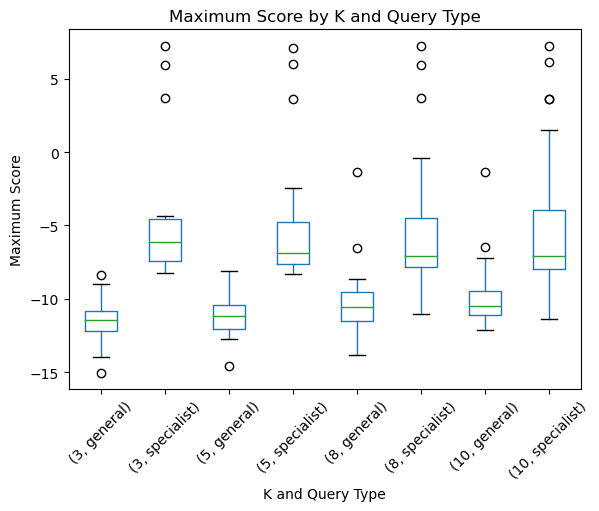

In [10]:
import matplotlib.pyplot as plt

df.boxplot(
    column="max_score",
    by=["k", "binary_expected"],
    grid=False
)

plt.title("Maximum Score by K and Query Type")
plt.suptitle("")
plt.xlabel("K and Query Type")
plt.ylabel("Maximum Score")
plt.xticks(rotation=45)
plt.show()

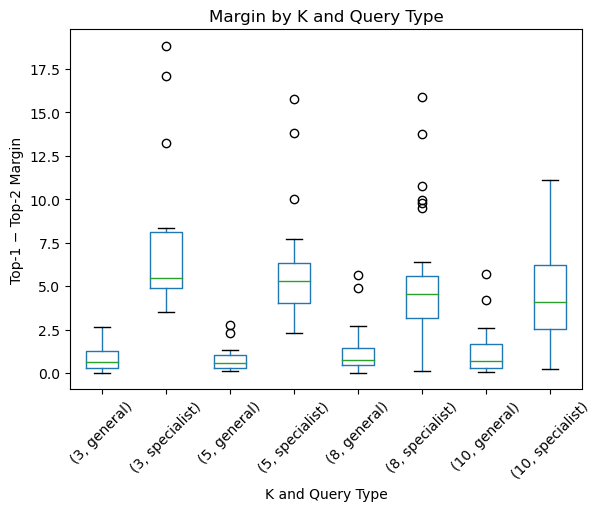

In [11]:
df.boxplot(
    column="margin",
    by=["k", "binary_expected"],
    grid=False
)

plt.title("Margin by K and Query Type")
plt.suptitle("")
plt.xlabel("K and Query Type")
plt.ylabel("Top-1 − Top-2 Margin")
plt.xticks(rotation=45)
plt.show()

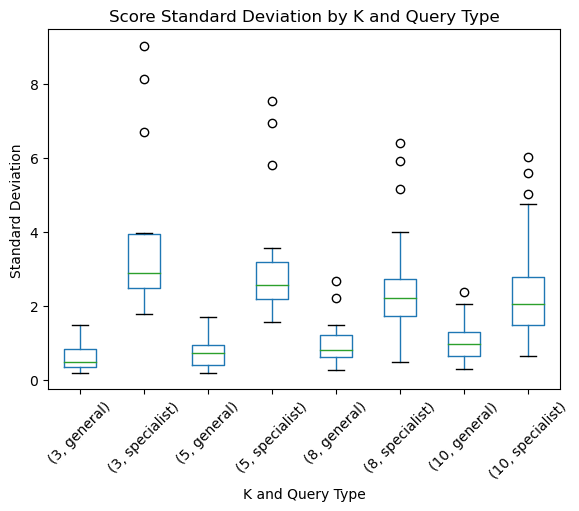

In [12]:
df.boxplot(
    column="std",
    by=["k", "binary_expected"],
    grid=False
)

plt.title("Score Standard Deviation by K and Query Type")
plt.suptitle("")
plt.xlabel("K and Query Type")
plt.ylabel("Standard Deviation")
plt.xticks(rotation=45)
plt.show()

In [13]:
def get_binary_target(label):
    if label == "specialist":
        return 1
    else:
        return 0


df["binary_target"] = df["binary_expected"].apply(get_binary_target)

In [14]:
from sklearn.metrics import roc_auc_score

results = []

for k in [3, 5, 8, 10]:

    df_k = df[df["k"] == k]

    max_auc = roc_auc_score(
        df_k["binary_target"],
        df_k["max_score"]
    )

    margin_auc = roc_auc_score(
        df_k["binary_target"],
        df_k["margin"]
    )

    std_auc = roc_auc_score(
        df_k["binary_target"],
        df_k["std"]
    )

    results.append({
        "k": k,
        "max_auc": max_auc,
        "margin_auc": margin_auc,
        "std_auc": std_auc
    })

auc_df = pd.DataFrame(results)

auc_df

,k,max_auc,margin_auc,std_auc
0,3,1.0000,1.0000,1.0000
1,5,0.9968,0.9968,0.9936
2,8,0.9150,0.8875,0.9040
3,10,0.8952,0.8788,0.8864
